# Лабораторная № 7, вариант 5 «Scrapy-краулер» — анализ прогонов

Источник данных — только файлы прогонов: структурные журналы `logs/run_*.jsonl`, отчёты `reports/run_report_*.json`, сводки `reports/*_summary.json`. Блокнот исполняется после `./run_real.sh` (*Restart & Run All*).

**Две группы прогонов.** Метки без префикса (`A`, `B`, `C`, `S1_cond`, `httpbin_*`, `real_*`) — реальные учебные площадки. Метки `mock_*` — локальная имитация (`tools/mock_shop.py`): на ней воспроизводятся отказы, которые нельзя вызывать на чужом сайте (429 с Retry-After, рост латентности, заглушка-капча, авария домена). Цифры имитации в отчёт идут только с пометкой «(на локальной имитации)».

| Раздел | Содержание |
|---|---|
| 1 | все прогоны: сводная таблица |
| 2 | robots.txt: can_fetch, Crawl-delay, Request-rate, Sitemap |
| 3 | классификация ошибок и журнал попыток (Retry-After vs backoff) |
| 4 | сценарий 429 от домена |
| 5 | срабатывание AutoThrottle (график задержки и латентности) |
| 6 | прерывание и возобновление |
| 7 | предохранитель: изоляция отказа домена |
| 8 | экономия нагрузки, прогоны A/B/C |
| 9 | детектор блокировок и сравнение с историей |
| 10 | отчёт о прогоне, пороги и оповещения |
| 11 | графики: распределение латентности, коды ответа во времени |
| 12 | лимит при 4 процессах |

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src.retry import classification_table
from src.observability import evaluate_alerts, THRESHOLDS

REP, LOGS = ROOT / "reports", ROOT / "logs"

def report(label):
    p = REP / f"run_report_{label}.json"
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None

def events(label):
    files = sorted(LOGS.glob(f"run_{label}_2*.jsonl"))
    if not files:
        return pd.DataFrame()
    df = pd.read_json(files[-1], lines=True)
    df["t"] = (pd.to_datetime(df["ts"]) - pd.to_datetime(df["ts"]).min()).dt.total_seconds()
    return df

def first_existing(*labels):
    for lab in labels:
        if report(lab):
            return lab
    return None

reports = {p.stem.replace("run_report_", ""): json.loads(p.read_text(encoding="utf-8"))
           for p in sorted(REP.glob("run_report_*.json"))}
print("Отчётов о прогонах:", len(reports))
print("Реальные:", [k for k in reports if not reports[k].get("local_mock")])
print("Имитация:", [k for k in reports if reports[k].get("local_mock")])

Отчётов о прогонах: 33
Реальные: ['A', 'B', 'C', 'S0_base', 'S1_cond', 'S2_gzip', 'S3_incr', 'httpbin_codes', 'httpbin_etag_repeat', 'real_breaker', 'real_resume_1', 'real_resume_2']
Имитация: ['mock_429', 'mock_429_polite', 'mock_A', 'mock_B', 'mock_C', 'mock_S0_base', 'mock_S1_cond', 'mock_S2_gzip', 'mock_S3_incr', 'mock_S4_after_change', 'mock_autothrottle', 'mock_breaker', 'mock_hist_1', 'mock_hist_2', 'mock_hist_3', 'mock_hist_captcha', 'mock_probe_503_timeout', 'mock_probe_codes', 'mock_probe_etag_repeat', 'mock_resume_1', 'mock_resume_2']


## 1. Все прогоны

In [2]:
cols = ["mode", "requests", "error_rate", "share_429_403", "retries", "latency_median_ms", "latency_p95_ms",
        "traffic_kb", "not_modified_304", "incremental_skipped", "breaker_activations", "incidents",
        "items_scraped", "items_dropped", "deferred_urls", "duration_s", "status", "local_mock"]
overview = pd.DataFrame({k: {c: r.get(c) for c in cols} for k, r in reports.items()}).T
overview

,mode,requests,error_rate,share_429_403,retries,latency_median_ms,latency_p95_ms,traffic_kb,not_modified_304,incremental_skipped,breaker_activations,incidents,items_scraped,items_dropped,deferred_urls,duration_s,status,local_mock
A,A,18,0.0556,0.0,0,2546.9,6284.5,1019.9,0,0,0,0,15,0,0,8.8,красный,False
B,B,18,0.0,0.0,0,800.6,1384.4,1082.9,0,0,0,0,16,0,0,23.41,зелёный,False
C,C,2,0.0,0.0,0,1218.5,1589.8,13.3,0,16,0,0,0,0,0,2.88,зелёный,False
S0_base,B,18,0.0,0.0,0,803.9,1103.5,1083.1,0,0,0,0,16,0,0,21.25,зелёный,False
S1_cond,B,18,0.0,0.0,0,834.0,1185.1,1082.9,0,0,0,0,16,0,0,21.03,зелёный,False
S2_gzip,B,18,0.0,0.0,0,837.2,1408.4,241.6,0,0,0,0,16,0,0,22.8,зелёный,False
S3_incr,B,3,0.3333,0.0,1,894.5,958.6,73.7,0,16,0,0,0,0,0,3.61,красный,False
httpbin_codes,B,12,0.5833,0.4167,3,229.4,659.5,1.0,0,0,0,1,0,0,1,14.73,красный,False
httpbin_etag_repeat,B,2,0.0,0.0,0,505.1,749.5,0.0,1,0,0,0,0,0,0,1.31,зелёный,False
mock_429,B,40,0.125,0.125,5,19.4,24.3,215.8,0,0,0,0,30,2,0,16.98,красный,True


## 2. robots.txt

`can_fetch` — итог по более строгому из двух парсеров: `urllib.robotparser` (требование задания) и Protego (RFC 9309, его использует Scrapy). Python ≤ 3.12 не понимает шаблоны `*`/`$`: на правило `Disallow: /ecommerce/*` (так закрыт scrapingcourse.com) он ответил бы «можно».

In [3]:
rows = []
sources = []
for rr in sorted(REP.glob("robots_report_*.json")):
    sources += json.loads(rr.read_text(encoding="utf-8"))
for r in reports.values():
    sources += r.get("robots") or []
seen = set()
for r in sources:
    key = (r.get("origin"), r.get("status"))
    if key in seen:
        continue
    seen.add(key)
    rows.append({"сайт": r.get("origin"), "HTTP": r.get("status"), "Crawl-delay": r.get("crawl_delay"),
                 "Request-rate": r.get("request_rate"), "Sitemap": ", ".join(r.get("sitemaps") or []) or "—",
                 "can_fetch": "; ".join(f"{u.split('://')[-1]} → {ok}" for u, ok in (r.get("can_fetch") or {}).items()),
                 "трактовка": r.get("policy_note")})
pd.DataFrame(rows)

,сайт,HTTP,Crawl-delay,Request-rate,Sitemap,can_fetch,трактовка
0,http://127.0.0.1:18507,404,NaN,None,—,127.0.0.1:18507/ecommerce/ → True; 127.0.0.1:18507/ecommerce/page/2/ → True;...,"HTTP 404: файла нет — явных запретов нет, но это не разрешение на любую нагр..."
1,https://httpbin.org,200,NaN,None,—,httpbin.org/ → True; httpbin.org/page/2/ → True,robots.txt найден: применяются его правила; Crawl-delay имеет приоритет над ...
2,https://scrapeme.live,200,NaN,None,https://scrapeme.live/wp-sitemap.xml,scrapeme.live/shop/ → True; scrapeme.live/shop/page/2/ → True,robots.txt найден: применяются его правила; Crawl-delay имеет приоритет над ...
3,http://127.0.0.1:18507,200,0.2,None,http://127.0.0.1:18507/wp-sitemap.xml,127.0.0.1:18507/ecommerce/ → True; 127.0.0.1:18507/ecommerce/page/2/ → True;...,robots.txt найден: применяются его правила; Crawl-delay имеет приоритет над ...
4,http://localhost:18508,200,0.2,None,http://localhost:18508/wp-sitemap.xml,localhost:18508/status/200 → True,robots.txt найден: применяются его правила; Crawl-delay имеет приоритет над ...


## 3. Классификация ошибок и журнал попыток

In [4]:
display(pd.DataFrame(classification_table()))
lab = first_existing("httpbin_codes", "mock_probe_codes")
ev = events(lab) if lab else pd.DataFrame()
print("Журнал попыток прогона:", lab, "(на локальной имитации)" if lab and lab.startswith("mock") else "")
if len(ev):
    keep = ev[ev["event"].isin(["request", "retry", "giveup", "auth_required", "incident", "probe_result"])]
    cols = [c for c in ["t", "event", "url", "status", "attempt", "delay_s", "delay_source", "retry_after_header",
                        "reason", "error_class", "retry_after_parsed_s", "verdict"] if c in keep]
    display(keep[cols].round(2))

,код/ситуация,класс,повторять,действие
0,200,success,нет,—
1,304,not_modified,нет,ресурс не изменился: берём сохранённую версию
2,301,redirect,нет,следуем редиректу (RedirectMiddleware)
3,400,client_error,нет,в журнал; ошибка запроса
4,401,auth_required,нет,обновить токен; без авторизации — прекратить попытки
5,403,forbidden_possible_block,нет,без повторов; инцидент → детектор блокировок
6,404,not_found,нет,в журнал; URL исключить
7,408,request_timeout,да,повтор с backoff
8,422,client_error,нет,в журнал; ошибка запроса
9,429,rate_limited,да,снизить скорость домена; ждать Retry-After или backoff


Журнал попыток прогона: httpbin_codes 


,t,event,url,status,attempt,delay_s,delay_source,retry_after_header,reason,error_class,retry_after_parsed_s,verdict
4,0.81,request,https://httpbin.org/robots.txt,200,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,1.40,request,https://httpbin.org/status/429,429,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16,1.40,retry,https://httpbin.org/status/429,429,1.0,0.58,backoff,NaN,rate_limited,NaN,NaN,NaN
19,2.37,request,https://httpbin.org/status/401,401,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20,2.37,auth_required,https://httpbin.org/status/401,401,NaN,NaN,NaN,NaN,"нужна авторизация: сбор идёт без учётных данных, обновлять нечего — без повт...",NaN,NaN,NaN
21,2.37,probe_result,https://httpbin.org/status/401,401,NaN,NaN,NaN,NaN,NaN,auth_required,NaN,NaN
23,3.38,request,https://httpbin.org/status/403,403,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
24,3.38,incident,https://httpbin.org/status/403,403,NaN,NaN,NaN,NaN,NaN,NaN,NaN,подозрение
25,3.38,probe_result,https://httpbin.org/status/403,403,NaN,NaN,NaN,NaN,NaN,forbidden_possible_block,NaN,NaN
27,4.39,request,https://httpbin.org/status/404,404,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Сценарий варианта: 429 от домена

In [5]:
for lab in [l for l in ("mock_429", "mock_429_polite") if report(l)]:
    r = report(lab)
    print(f"{lab}: запросов {r['requests']}, коды {r['status_counts']}, повторов {r['retries']} "
          f"(источники задержки {r['retry_sources']}), записей {r['items_scraped']}, {r['duration_s']} с (на локальной имитации)")
ev = events("mock_429")
if len(ev):
    cols = [c for c in ["t", "event", "url", "status", "attempt", "delay_s", "delay_source", "retry_after_header",
                        "pause_s", "source", "adaptive_delay_s"] if c in ev]
    display(ev[ev["event"].isin(["retry", "domain_pause", "giveup"])][cols].round(3))

mock_429: запросов 40, коды {'200': 35, '429': 5}, повторов 5 (источники задержки {'retry-after': 4, 'backoff': 1}), записей 30, 16.98 с (на локальной имитации)
mock_429_polite: запросов 35, коды {'200': 35}, повторов 0 (источники задержки {'retry-after': 0, 'backoff': 0}), записей 30, 16.66 с (на локальной имитации)


,t,event,url,status,attempt,delay_s,delay_source,retry_after_header,pause_s,source,adaptive_delay_s
45,3.622,domain_pause,http://127.0.0.1:18507/ecommerce/product/karissa-yoga-pant/,429,NaN,NaN,NaN,NaN,1.000,retry-after,1.000
46,3.622,retry,http://127.0.0.1:18507/ecommerce/product/karissa-yoga-pant/,429,1.0,1.000,retry-after,1,NaN,NaN,NaN
55,4.301,domain_pause,http://127.0.0.1:18507/ecommerce/product/didi-backpack/,429,NaN,NaN,NaN,NaN,1.239,retry-after,1.142
56,4.302,retry,http://127.0.0.1:18507/ecommerce/product/didi-backpack/,429,1.0,1.239,retry-after,"Fri, 16 Oct 2026 12:26:31 GMT",NaN,NaN,NaN
66,5.252,domain_pause,http://127.0.0.1:18507/ecommerce/page/2/,429,NaN,NaN,NaN,NaN,1.000,adaptive_delay,1.000
67,5.252,retry,http://127.0.0.1:18507/ecommerce/page/2/,429,1.0,0.456,backoff,NaN,NaN,NaN,NaN
118,13.976,domain_pause,http://127.0.0.1:18507/ecommerce/product/selene-sweatshirt/,429,NaN,NaN,NaN,NaN,1.000,retry-after,1.000
119,13.976,retry,http://127.0.0.1:18507/ecommerce/product/selene-sweatshirt/,429,1.0,1.000,retry-after,1,NaN,NaN,NaN
127,14.675,domain_pause,http://127.0.0.1:18507/ecommerce/product/stellar-foam-roller/,429,NaN,NaN,NaN,NaN,1.865,retry-after,1.141
128,14.675,retry,http://127.0.0.1:18507/ecommerce/product/stellar-foam-roller/,429,1.0,1.865,retry-after,"Fri, 16 Oct 2026 12:26:42 GMT",NaN,NaN,NaN


## 5. Сценарий варианта: срабатывание AutoThrottle

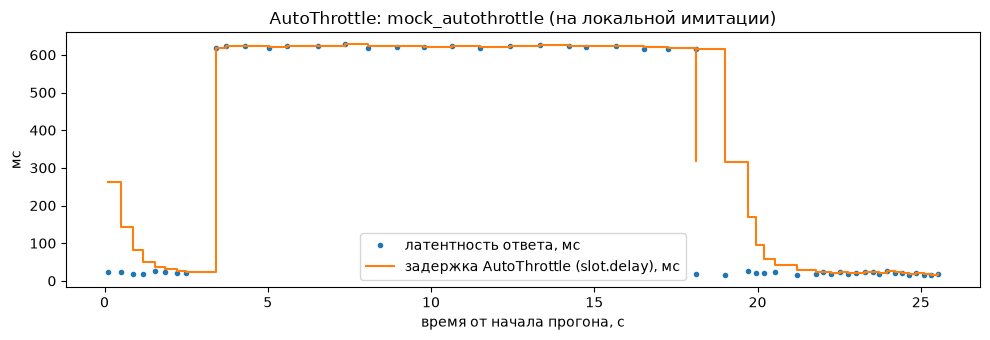

mock_autothrottle задержка AutoThrottle, мс: мин 16.8 макс 629.0


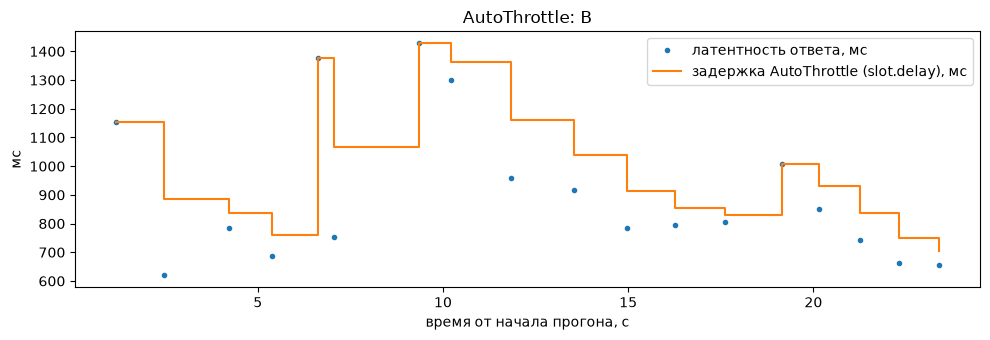

B задержка AutoThrottle, мс: мин 703.1 макс 1429.3


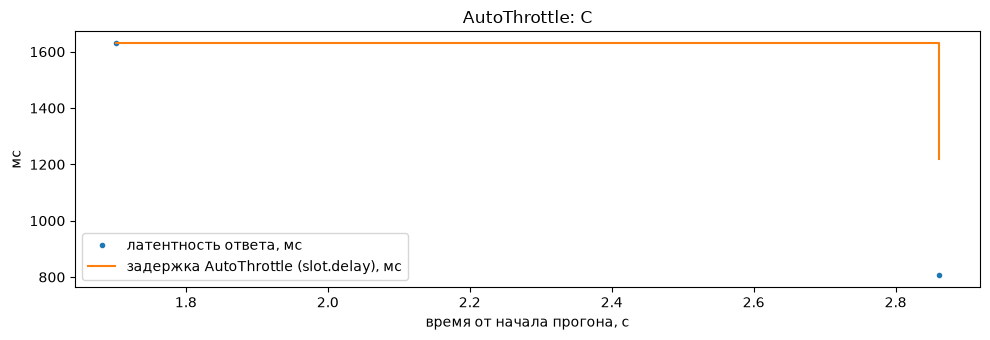

C задержка AutoThrottle, мс: мин 1218.5 макс 1631.1


In [6]:
lab = first_existing("B", "mock_autothrottle")
for lab in [l for l in ("mock_autothrottle", "B", "C") if report(l)]:
    ev = events(lab)
    at = ev[ev["event"] == "autothrottle"]
    if not len(at):
        continue
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.plot(at["t"], at["ms"], ".", label="латентность ответа, мс")
    ax.step(at["t"], at["delay_ms"], where="post", label="задержка AutoThrottle (slot.delay), мс")
    ax.set_xlabel("время от начала прогона, с"); ax.set_ylabel("мс"); ax.legend()
    ax.set_title(f"AutoThrottle: {lab}" + (" (на локальной имитации)" if report(lab).get("local_mock") else ""))
    plt.tight_layout(); plt.show()
    print(lab, "задержка AutoThrottle, мс: мин", at["delay_ms"].min(), "макс", at["delay_ms"].max())

## 6. Сценарий варианта: прерывание и возобновление

In [7]:
for name in ("real_resume_summary.json", "mock_resume_summary.json"):
    p = REP / name
    if p.exists():
        s = json.loads(p.read_text(encoding="utf-8"))
        print(name, "(на локальной имитации)" if s.get("local_mock") else "")
        display(pd.DataFrame([{"прогон": "1 (SIGINT)", **{k: v for k, v in s["run1"].items() if k != "scrapy_stats"}},
                              {"прогон": "2 (возобновление)", **{k: v for k, v in s["run2"].items() if k != "scrapy_stats"}}]))
        print("Файлы JOBDIR после прерывания:", *s["jobstate_files"], sep="\n  ")
        print("Записей в БД по прогонам:", s["db_rows_by_run"])

real_resume_summary.json 


,прогон,close_reason,requests,items,dupefilter/filtered
0,1 (SIGINT),shutdown,7,5,NaN
1,2 (возобновление),finished,30,27,17.0


Файлы JOBDIR после прерывания:
  jobstate/real_resume/requests.queue/active.json (2 Б)
  jobstate/real_resume/requests.seen (374 Б)
  jobstate/real_resume/spider.state (5 Б)
Записей в БД по прогонам: [['real_resume_1_20261016T144823Z', 5], ['real_resume_2_20261016T144834Z', 27]]
mock_resume_summary.json (на локальной имитации)


,прогон,close_reason,requests,items,dupefilter/filtered
0,1 (SIGINT),shutdown,19,15,NaN
1,2 (возобновление),finished,35,31,17.0


Файлы JOBDIR после прерывания:
  jobstate/mock_resume/requests.queue/127.0.0.1-f528764d624db129b32c21fbca0cb8d6/-10 (9491 Б)
  jobstate/mock_resume/requests.queue/127.0.0.1-f528764d624db129b32c21fbca0cb8d6/0 (343 Б)
  jobstate/mock_resume/requests.queue/active.json (23 Б)
  jobstate/mock_resume/requests.seen (748 Б)
  jobstate/mock_resume/spider.state (5 Б)
Записей в БД по прогонам: [['mock_resume_1_20261016T122726Z', 15], ['mock_resume_2_20261016T122735Z', 31]]


## 7. Предохранитель: изоляция отказа домена

real_breaker  | предохранитель: {'scrapeme.live': {'state': 'closed', 'activations': 0, 'rejected': 0}, 'httpbin.org': {'state': 'closed', 'activations': 1, 'rejected': 14}}


,t,host,from_state,to_state,reason
57,8.4,httpbin.org,closed,open,3 отказов подряд (HTTP 503); пауза 5 с
94,13.4,httpbin.org,open,half-open,пауза 5 с истекла — пробный запрос
146,21.1,httpbin.org,half-open,closed,пробный запрос успешен


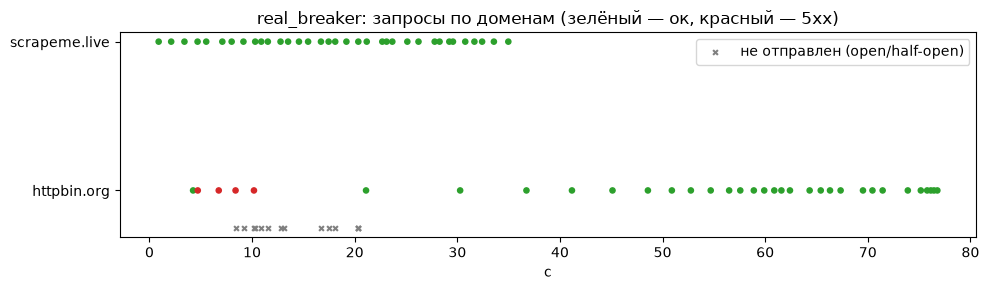

mock_breaker (на локальной имитации) | предохранитель: {'127.0.0.1:18507': {'state': 'closed', 'activations': 0, 'rejected': 0}, 'localhost:18508': {'state': 'closed', 'activations': 1, 'rejected': 51}}


,t,host,from_state,to_state,reason
54,4.1,localhost:18508,closed,open,3 отказов подряд (HTTP 503); пауза 5 с
130,9.5,localhost:18508,open,half-open,пауза 5 с истекла — пробный запрос
237,16.1,localhost:18508,half-open,closed,пробный запрос успешен


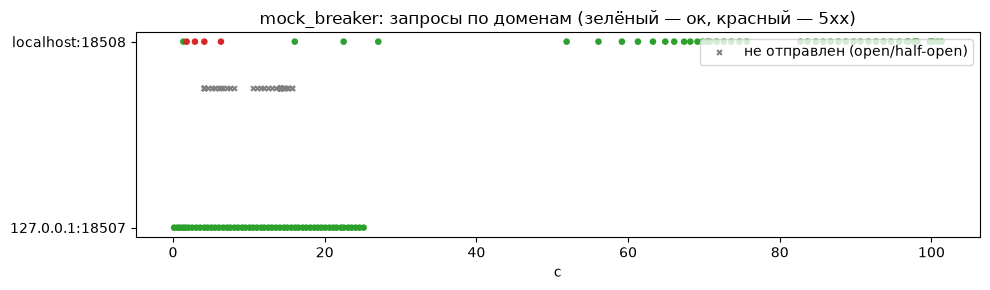

In [8]:
for lab in [l for l in ("real_breaker", "mock_breaker") if report(l)]:
    ev = events(lab)
    print(lab, "(на локальной имитации)" if report(lab).get("local_mock") else "", "| предохранитель:", report(lab)["breakers"])
    br = ev[ev["event"] == "breaker"]
    if br.empty:
        print("  переходов предохранителя в этом прогоне не зафиксировано (домен не набрал порог отказов подряд)")
    else:
        display(br.reindex(columns=["t", "host", "from_state", "to_state", "reason"]).round(1))
    req = ev[ev["event"] == "request"]
    fig, ax = plt.subplots(figsize=(10, 3))
    for i, (host, g) in enumerate(req.groupby("host")):
        ax.scatter(g["t"], [i] * len(g), c=["tab:red" if (s or 0) >= 500 else "tab:green" for s in g["status"]], s=14)
    rej = ev[ev["event"] == "breaker_reject"]
    hosts = list(req.groupby("host").groups)
    ax.scatter(rej["t"], [hosts.index(h) - 0.25 if h in hosts else 0 for h in rej["host"]], marker="x", c="gray", s=12,
               label="не отправлен (open/half-open)")
    ax.set_yticks(range(len(hosts))); ax.set_yticklabels(hosts); ax.set_xlabel("с"); ax.legend(loc="upper right")
    ax.set_title(f"{lab}: запросы по доменам (зелёный — ок, красный — 5xx)")
    plt.tight_layout(); plt.show()

## 8. Экономия нагрузки и прогоны A/B/C

# Сравнение прогонов

Трафик — байты тел ответов «на проводе» (до распаковки gzip), из JSON-журнала. Запросы — сетевые попытки, включая robots.txt и повторы.

## Реальный сайт (согласованный учебный источник)

### Прогоны A / B / C (одинаковый объём: 1 страница каталога + её карточки)

| Прогон | Настройки | Время, с | Запросов | Трафик, КБ | Доля ошибок | 429/403 | Повторов | Ответов 304 | Пропущено (инкр.) | Записей |
|---|---|---|---|---|---|---|---|---|---|---|
| A | без лимита, без повторов, без условных запросов | 8.8 | 18 | 1019.9 | 5.6% | 0.0% | 0 | 0 | 0 | 15 |
| B | token bucket + адаптивная задержка + AutoThrottle + повторы + предохранитель | 23.41 | 18 | 1082.9 | 0.0% | 0.0% | 0 | 0 | 0 | 16 |
| C | B + ETag/Last-Modified + gzip + «водяной знак» (повторный прогон после B) | 2.88 | 2 | 13.3 | 0.0% | 0.0% | 0 | 0 | 16 | 0 |

Цена вежливости: B медленнее A на 14.6 с (23.4 против 8.8 с); при этом A получил 0 ответов 429 и собрал 15 записей против 16 у B.
Выигрыш C относительно B: трафик 1082.9 → 13.3 КБ (−98.8 %), запросов 18 → 2.

### Экономия нагрузки по механизмам

| Механизм | Сравнение | Запросов до | Запросов после | Трафик до, КБ | Трафик после, КБ | Экономия трафика, % | Экономия запросов, % |
|---|---|---|---|---|---|---|---|
| Условные запросы (ETag / Last-Modified → 304) | S0 → S1 | 18 | 18 | 1083.1 | 1082.9 | 0.0 | 0.0 |
| Сжатие (Accept-Encoding: gzip) | S0 → S2 | 18 | 18 | 1083.1 | 241.6 | 77.7 | 0.0 |
| Инкрементальность («водяной знак» + 304 на каталоге) | S1 → S3 | 18 | 3 | 1082.9 | 73.7 | 93.2 | 83.3 |
| Все механизмы вместе | B → C | 18 | 2 | 1082.9 | 13.3 | 98.8 | 88.9 |

## Локальная имитация (tools/mock_shop.py) — цифры только «(на локальной имитации)»

### Прогоны A / B / C (одинаковый объём: 1 страница каталога + её карточки)

| Прогон | Настройки | Время, с | Запросов | Трафик, КБ | Доля ошибок | 429/403 | Повторов | Ответов 304 | Пропущено (инкр.) | Записей |
|---|---|---|---|---|---|---|---|---|---|---|
| A | без лимита, без повторов, без условных запросов | 0.14 | 18 | 42.6 | 66.7% | 66.7% | 0 | 0 | 0 | 4 |
| B | token bucket + адаптивная задержка + AutoThrottle + повторы + предохранитель | 8.08 | 18 | 107.7 | 0.0% | 0.0% | 0 | 0 | 0 | 15 |
| C | B + ETag/Last-Modified + gzip + «водяной знак» (повторный прогон после B) | 0.47 | 2 | 0.1 | 0.0% | 0.0% | 0 | 1 | 16 | 0 |

Цена вежливости: B медленнее A на 7.9 с (8.1 против 0.1 с); при этом A получил 12 ответов 429 и собрал 4 записей против 15 у B.
Выигрыш C относительно B: трафик 107.7 → 0.1 КБ (−99.9 %), запросов 18 → 2.

### Экономия нагрузки по механизмам

| Механизм | Сравнение | Запросов до | Запросов после | Трафик до, КБ | Трафик после, КБ | Экономия трафика, % | Экономия запросов, % |
|---|---|---|---|---|---|---|---|
| Условные запросы (ETag / Last-Modified → 304) | S0 → S1 | 18 | 18 | 107.7 | 0.2 | 99.8 | 0.0 |
| Сжатие (Accept-Encoding: gzip) | S0 → S2 | 18 | 18 | 107.7 | 31.3 | 70.9 | 0.0 |
| Инкрементальность («водяной знак» + 304 на каталоге) | S1 → S3 | 18 | 2 | 0.2 | 0.2 | 0.0 | 88.9 |
| Все механизмы вместе | B → C | 18 | 2 | 107.7 | 0.1 | 99.9 | 88.9 |



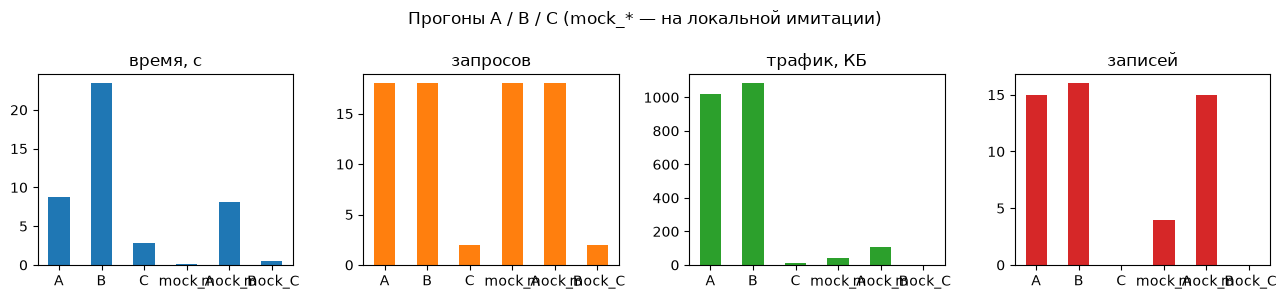

In [9]:
cmp_md = REP / "comparison.md"
if cmp_md.exists():
    from IPython.display import Markdown
    display(Markdown(cmp_md.read_text(encoding="utf-8")))
abc = [l for l in ("A", "B", "C", "mock_A", "mock_B", "mock_C") if report(l)]
if abc:
    df = pd.DataFrame({l: {"время, с": report(l)["duration_s"], "запросов": report(l)["requests"],
                           "трафик, КБ": report(l)["traffic_kb"], "записей": report(l)["items_scraped"]} for l in abc}).T
    df.plot(kind="bar", subplots=True, layout=(1, 4), figsize=(13, 3), legend=False, rot=0)
    plt.suptitle("Прогоны A / B / C (mock_* — на локальной имитации)"); plt.tight_layout(); plt.show()

## 9. Детектор блокировок и сравнение с историей

In [10]:
inc = sorted((LOGS / "incidents").glob("*/meta.json"))
rows = [json.loads(p.read_text(encoding="utf-8")) | {"артефакты": str(p.parent.relative_to(ROOT))} for p in inc]
if rows:
    display(pd.DataFrame(rows)[["run_id", "url", "status", "bytes", "verdict", "signals", "артефакты"]])
for lab in [l for l in ("mock_hist_captcha", "B") if report(l)]:
    h = report(lab).get("history") or {}
    print(f"{lab}: статус истории — {h.get('status')}; предыдущих прогонов {h.get('previous_runs')}")
    if h.get("checks"):
        display(pd.DataFrame(h["checks"]))

,run_id,url,status,bytes,verdict,signals,артефакты
0,httpbin_codes_20261016T122445Z,https://httpbin.org/status/403,403,0,подозрение,[код 403],logs/incidents/httpbin_codes_20261016T122445Z_001_httpbin.org_status_403
1,mock_hist_captcha_20261016T123002Z,http://127.0.0.1:18507/ecommerce/page/2/,200,214,блокировка,"[маркеры: captcha, are you human, access denied, cf-browser-verification, ан...",logs/incidents/mock_hist_captcha_20261016T123002Z_001_127.0.0.1_18507_ecomme...
2,mock_probe_codes_20261016T123008Z,http://127.0.0.1:18507/status/403,403,10,подозрение,[код 403],logs/incidents/mock_probe_codes_20261016T123008Z_001_127.0.0.1_18507_status_403


mock_hist_captcha: статус истории — красный; предыдущих прогонов 3


,проверка,значение,порог,статус
0,записей к медиане,0.500,≥ 80%,красный
1,средний размер ответа к медиане,0.922,≥ 70%,ок


B: статус истории — нет истории; предыдущих прогонов 0


## 10. Отчёт о прогоне: пороги и оповещения

In [11]:
display(pd.DataFrame([{"метрика": t.key, "условие": f"{t.op} {t.value}", "уровень": t.severity, "обоснование": t.why}
                      for t in THRESHOLDS]))
rows = []
for lab, r in reports.items():
    for a in r.get("alerts", []):
        rows.append({"прогон": lab, **a})
pd.DataFrame(rows) if rows else "оповещений нет"

,метрика,условие,уровень,обоснование
0,error_rate,> 0.05,красный,больше 5 % ошибок — сбор неполный; на учебной площадке норма — 0
1,share_429_403,> 0.01,жёлтый,429/403 — сайт просит снизить нагрузку или ограничил доступ; вежливый сборщи...
2,latency_p95_ms,> 3000,жёлтый,p95 > 3 с — сервер перегружен (в том числе нами): лимит надо снизить
3,retries_per_request,> 0.1,жёлтый,больше одного повтора на 10 запросов — нестабильность или слишком высокая ск...
4,breaker_activations,> 0,жёлтый,"срабатывание предохранителя — домен был недоступен, часть URL отложена"
5,incidents_block,> 0,красный,"детектор нашёл заглушку/блокировку — сбор домена остановлен, нужен разбор"
6,items_vs_median,< 0.8,красный,записей меньше 80 % медианы прошлых прогонов — поломка селекторов или тихая ...
7,avg_bytes_vs_median,< 0.7,красный,средний ответ меньше 70 % медианы — сайт отдаёт заглушки или урезанные страницы


,прогон,порог,значение,уровень,обоснование
0,A,error_rate > 0.05,0.055600,красный,больше 5 % ошибок — сбор неполный; на учебной площадке норма — 0
1,A,latency_p95_ms > 3000,6284.500000,жёлтый,p95 > 3 с — сервер перегружен (в том числе нами): лимит надо снизить
2,S3_incr,error_rate > 0.05,0.333300,красный,больше 5 % ошибок — сбор неполный; на учебной площадке норма — 0
3,S3_incr,retries_per_request > 0.1,0.333333,жёлтый,больше одного повтора на 10 запросов — нестабильность или слишком высокая ск...
4,httpbin_codes,error_rate > 0.05,0.583300,красный,больше 5 % ошибок — сбор неполный; на учебной площадке норма — 0
5,httpbin_codes,share_429_403 > 0.01,0.416700,жёлтый,429/403 — сайт просит снизить нагрузку или ограничил доступ; вежливый сборщи...
6,httpbin_codes,retries_per_request > 0.1,0.250000,жёлтый,больше одного повтора на 10 запросов — нестабильность или слишком высокая ск...
7,mock_429,error_rate > 0.05,0.125000,красный,больше 5 % ошибок — сбор неполный; на учебной площадке норма — 0
8,mock_429,share_429_403 > 0.01,0.125000,жёлтый,429/403 — сайт просит снизить нагрузку или ограничил доступ; вежливый сборщи...
9,mock_429,retries_per_request > 0.1,0.125000,жёлтый,больше одного повтора на 10 запросов — нестабильность или слишком высокая ск...


## 11. Графики по журналу: распределение латентности и коды ответа во времени

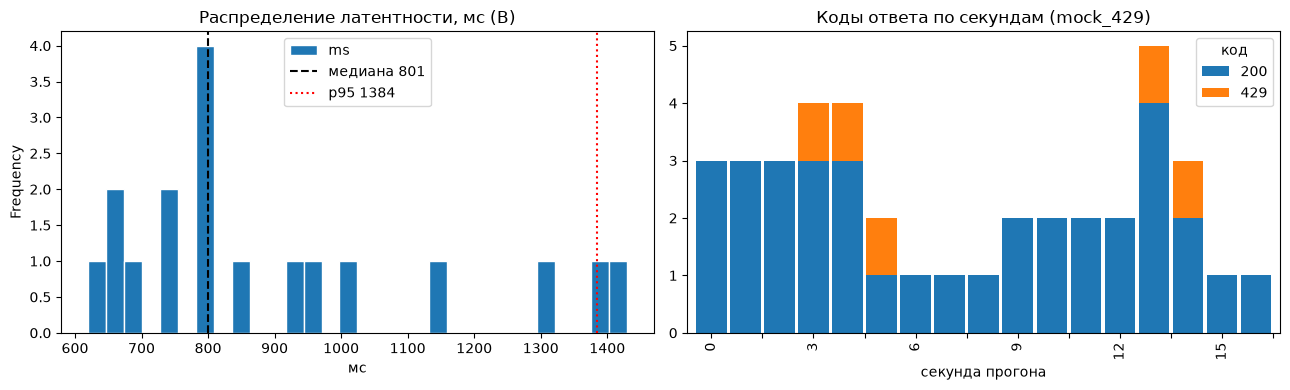

(для меток mock_* — на локальной имитации)


In [12]:
lab = first_existing("B", "C", "mock_429", "mock_B")
ev = events(lab)
req = ev[(ev["event"] == "request") & ev["ms"].notna()]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
req["ms"].plot(kind="hist", bins=30, ax=axes[0], edgecolor="white")
axes[0].set_title(f"Распределение латентности, мс ({lab})"); axes[0].set_xlabel("мс")
axes[0].axvline(req["ms"].median(), color="k", ls="--", label=f"медиана {req['ms'].median():.0f}")
axes[0].axvline(req["ms"].quantile(0.95), color="r", ls=":", label=f"p95 {req['ms'].quantile(0.95):.0f}")
axes[0].legend()
lab2 = first_existing("mock_429", "B")
ev2 = events(lab2)
r2 = ev2[ev2["event"] == "request"].copy()
r2["сек"] = r2["t"].astype(int)
r2["код"] = r2["status"].fillna(-1).astype(int).astype(str).replace({"-1": "сеть"})
r2.pivot_table(index="сек", columns="код", values="url", aggfunc="count", fill_value=0).plot(
    kind="bar", stacked=True, ax=axes[1], width=0.9)
axes[1].set_title(f"Коды ответа по секундам ({lab2})"); axes[1].set_xlabel("секунда прогона")
axes[1].xaxis.set_major_locator(plt.MaxNLocator(12))
plt.tight_layout(); plt.show()
print("(для меток mock_* — на локальной имитации)")

## 12. Лимит при 4 параллельных процессах

In [13]:
p = REP / "shared_limit.json"
if p.exists():
    s = json.loads(p.read_text(encoding="utf-8"))
    print("(на локальной имитации)" if s.get("local_mock") else "")
    display(pd.DataFrame(s["rows"]))
else:
    print("Нет reports/shared_limit.json: python3 tools/demo_shared_limit.py")

(на локальной имитации)


,режим,воркеров,"лимит, запр/с",запросов,"время, с","средняя скорость на сервере, запр/с",максимум за любую 1 с
0,local,4,2.0,32,3.65,8.89,12
1,shared,4,2.0,32,15.63,2.00,3


## Выводы

По реальному прогону 16.10.2026 (scrapeme.live, таблицы выше):

1. Цена вежливости (B против A): 14,6 с на одинаковом объёме (23,4 против 8,8 с). A не получил ни одного 429, но один обрыв соединения без повтора (5,6 % ошибок) стоил записи — 15 против 16, а p95 латентности сервера вырос до 6,3 с против 1,4 с у B.
2. Экономия трафика C против B: 98,8 %; запросов 18 → 2. На scrapeme.live условные запросы не дали ни одного 304 — экономия получена водяным знаком и gzip (−77,7 % трафика в S2).
3. AutoThrottle на реальном сайте менял задержку в диапазоне 703–1429 мс (прогон B) и 1219–1631 мс (прогон C) вслед за латентностью.
4. Возобновление: после прерывания повторно не запрошено 17 URL (dupefilter/filtered — 16 карточек первой страницы и ссылка на вторую), отложенные 12 URL дозабраны из `deferred.json`; в БД 5 + 27 = 32 записи и 32 разных SKU — дублей нет.